# JS08 Tugas Lab 1: Agglomerative Clustering pada Data Nasabah Kartu Kredit

Dataset yang dipakai sama dengan Tugas Lab JS07, berisi 660 nasabah dengan lima variabel yang bisa digunakan: `Avg_Credit_Limit`, `Total_Credit_Cards`, `Total_visits_bank`, `Total_visits_online`, dan `Total_calls_made`.

Kolom `Sl_No` dan `Customer Key` tidak dipakai karena keduanya hanya penanda identitas.


## 1. Import Library dan Load Data


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler
import scipy.cluster.hierarchy as sch


In [2]:
df = pd.read_csv('dataset/Credit_Card_Customer_Data.csv')
df.head()


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [3]:
print(df.shape)
print('Missing values:', df.isna().sum().sum())
df.describe().T[['mean', 'std', 'min', '50%', 'max']]


(660, 7)
Missing values: 0


,mean,std,min,50%,max
Sl_No,330.500000,190.669872,1.0,330.5,660.0
Customer Key,55141.443939,25627.772200,11265.0,53874.5,99843.0
Avg_Credit_Limit,34574.242424,37625.487804,3000.0,18000.0,200000.0
Total_Credit_Cards,4.706061,2.167835,1.0,5.0,10.0
Total_visits_bank,2.403030,1.631813,0.0,2.0,5.0
Total_visits_online,2.606061,2.935724,0.0,2.0,15.0
Total_calls_made,3.583333,2.865317,0.0,3.0,10.0


## 2. Preprocessing

Fitur distandarkan lebih dulu. Tanpa ini, `Avg_Credit_Limit` yang bernilai puluhan ribu akan mendominasi perhitungan jarak dan mengalahkan jumlah kunjungan yang cuma satuan.


In [4]:
fitur = list(df.columns[2:])
X = StandardScaler().fit_transform(df[fitur].values)

pd.DataFrame(X, columns=fitur).describe().T[['mean', 'std', 'min', 'max']]


,mean,std,min,max
Avg_Credit_Limit,8.612639e-17,1.000758,-0.839808,4.399975
Total_Credit_Cards,4.306320e-17,1.000758,-1.710864,2.443892
Total_visits_bank,-4.306320e-17,1.000758,-1.473731,1.592670
Total_visits_online,7.536059e-17,1.000758,-0.888380,4.224968
Total_calls_made,-8.612639e-17,1.000758,-1.251537,2.241125


## 3. Dendrogram untuk Melihat Struktur Hierarki

Dendrogram dihitung dari seluruh fitur, bukan hanya dua fitur yang divisualkan nanti. Menghitung linkage pada 660 titik cukup berat, jadi dendrogram digambar tanpa label daun.


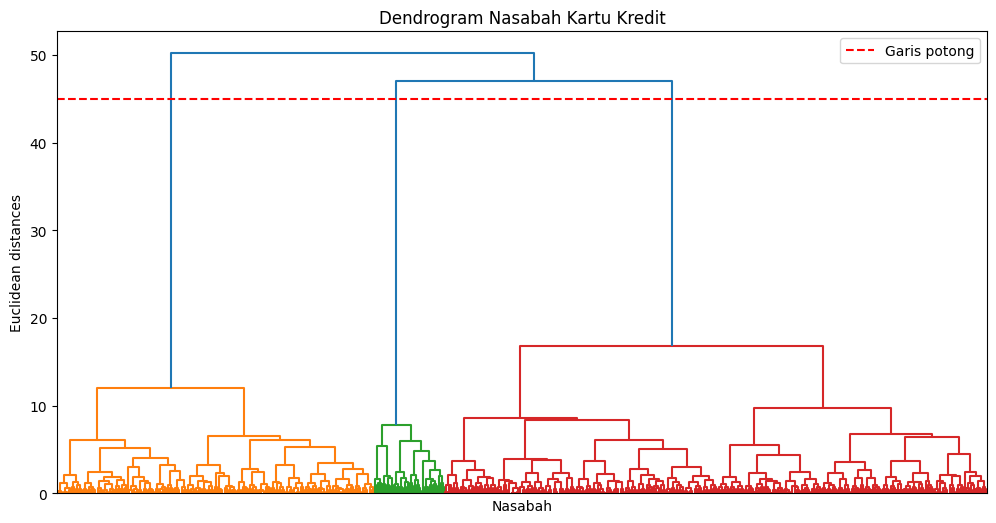

In [5]:
Z = sch.linkage(X, method='ward')

plt.figure(figsize=(12, 6))
sch.dendrogram(Z, no_labels=True)
plt.title('Dendrogram Nasabah Kartu Kredit')
plt.xlabel('Nasabah')
plt.ylabel('Euclidean distances')
plt.axhline(y=45, color='r', linestyle='--', label='Garis potong')
plt.legend()
plt.show()


In [6]:
for threshold in [30, 40, 45, 50, 60, 80]:
    jumlah = len(set(sch.fcluster(Z, t=threshold, criterion='distance')))
    print(f'Threshold {threshold}: {jumlah} cluster')


Threshold 30: 3 cluster
Threshold 40: 3 cluster
Threshold 45: 3 cluster
Threshold 50: 2 cluster
Threshold 60: 1 cluster
Threshold 80: 1 cluster


Ambang 30 sampai 45 memberi tiga cluster, 50 memberi dua, dan 60 ke atas menyatukan semuanya menjadi satu. Jadi daerah yang stabil untuk tiga cluster ada di rentang 30 sampai 45, dan garis potong 45 dipakai karena masih di batas atas rentang itu.


## 4. Memilih Jumlah Cluster

Jumlah cluster diuji dari 2 sampai 8 dengan dua metrik sekaligus, lalu dibandingkan dengan bacaan dendrogram.


In [7]:
hasil = []
for k in range(2, 9):
    model = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    label = model.fit_predict(X)
    hasil.append({
        'k': k,
        'Silhouette': round(silhouette_score(X, label), 4),
        'Davies-Bouldin': round(davies_bouldin_score(X, label), 4),
    })

pd.DataFrame(hasil)


,k,Silhouette,Davies-Bouldin
0,2,0.4177,0.9326
1,3,0.5148,0.6810
2,4,0.3481,1.1493
3,5,0.2569,1.3851
4,6,0.2268,1.4109
5,7,0.2163,1.4394
6,8,0.2187,1.4489


`k=3` memberi silhouette tertinggi (0.5148) dan DBI terkecil (0.6810). Setelah itu keduanya memburuk: `k=4` turun ke 0.3481 dan naik lagi ke 1.1493. Bacaan dendrogram juga sejalan, garis potong di ketinggian 45 menghasilkan tiga kelompok besar.


In [8]:
# Efek metode linkage terhadap hasil, sebagai pemeriksaan tambahan
linkage_uji = []
for metode in ['ward', 'complete', 'average', 'single']:
    model = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage=metode)
    label = model.fit_predict(X)
    linkage_uji.append({
        'Linkage': metode,
        'Silhouette': round(silhouette_score(X, label), 4),
        'Ukuran cluster': str(np.bincount(label)),
    })

pd.DataFrame(linkage_uji)


,Linkage,Silhouette,Ukuran cluster
0,ward,0.5148,[385 225 50]
1,complete,0.5026,[397 50 213]
2,average,0.5159,[387 50 223]
3,single,0.3743,[609 1 50]


`single` gagal di sini: ia menyisakan satu cluster berisi 609 anggota dan satu cluster beranggota satu. Metode itu memang rawan efek rantai, karena dua cluster bisa tergabung hanya karena ada satu titik yang menjembatani keduanya. `ward` dan `average` paling seimbang.


## 5. Model Final dan Scatterplot


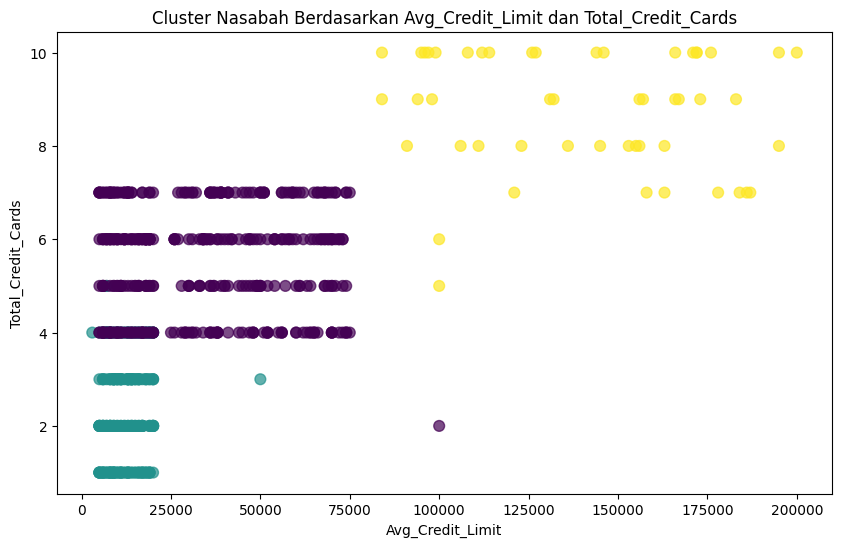

In [9]:
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X)

df['cluster'] = y_hc

plt.figure(figsize=(10, 6))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'],
            c=y_hc, s=60, cmap='viridis', alpha=0.7)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Cluster Nasabah Berdasarkan Avg_Credit_Limit dan Total_Credit_Cards')
plt.show()


In [10]:
profil = df.groupby('cluster')[fitur].mean().round(1)
profil['jumlah_nasabah'] = df['cluster'].value_counts().sort_index()
profil


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,jumlah_nasabah
cluster,,,,,,
0,33851.9,5.5,3.5,1.0,2.0,385
1,12151.1,2.4,0.9,3.5,6.9,225
2,141040.0,8.7,0.6,10.9,1.1,50


Ketiga cluster terpisah jelas pada dua fitur yang digambar: satu kelompok limit rendah dengan banyak panggilan, satu kelompok menengah yang aktif ke bank, dan satu kelompok limit tinggi yang aktif online. Pemisahan ini terbentuk dari kelima fitur, jadi wajar kalau tampilannya pada dua dimensi masih terlihat rapi.


## 6. Evaluasi Model


In [11]:
sil = silhouette_score(X, y_hc)
dbi = davies_bouldin_score(X, y_hc)

print(f'Silhouette Score: {sil:.4f}')
print(f'Davies-Bouldin Index: {dbi:.4f}')


Silhouette Score: 0.5148
Davies-Bouldin Index: 0.6810


In [12]:
# Bandingkan dengan hasil K-Means dan DBSCAN dari Tugas Lab JS07
from sklearn.cluster import DBSCAN, KMeans

label_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X)
label_dbscan = DBSCAN(eps=0.9, min_samples=5).fit_predict(X)
mask_db = label_dbscan != -1

perbandingan = pd.DataFrame([
    {'Model': 'Agglomerative (ward, k=3)', 'Jumlah cluster': 3,
     'Silhouette': silhouette_score(X, y_hc), 'Davies-Bouldin': davies_bouldin_score(X, y_hc)},
    {'Model': 'K-Means (k=3)', 'Jumlah cluster': 3,
     'Silhouette': silhouette_score(X, label_kmeans), 'Davies-Bouldin': davies_bouldin_score(X, label_kmeans)},
    {'Model': 'DBSCAN (eps=0.9, min_samples=5, tanpa noise)',
     'Jumlah cluster': len(set(label_dbscan[mask_db])),
     'Silhouette': silhouette_score(X[mask_db], label_dbscan[mask_db]),
     'Davies-Bouldin': davies_bouldin_score(X[mask_db], label_dbscan[mask_db])},
])
perbandingan.round(4)


,Model,Jumlah cluster,Silhouette,Davies-Bouldin
0,"Agglomerative (ward, k=3)",3,0.5148,0.6810
1,K-Means (k=3),3,0.5157,0.6797
2,"DBSCAN (eps=0.9, min_samples=5, tanpa noise)",3,0.4940,0.8784


Agglomerative dan K-Means memberi hasil yang hampir sama pada dataset ini, baik dari segi ukuran cluster maupun skornya. Itu masuk akal karena keduanya memakai jarak Euclidean dan mencari cluster yang padat, hanya berbeda cara mencapainya.

DBSCAN tetap paling berbeda karena ia mengeluarkan 27 titik sebagai noise dan hanya menyisakan cluster yang benar-benar rapat.


## Kesimpulan

Agglomerative Clustering dengan `linkage='ward'` menghasilkan tiga cluster, silhouette 0.5148 dan DBI 0.6810. Jumlah cluster itu dipilih dari perbandingan metrik pada `k=2` sampai `k=8` dan diperkuat oleh bacaan dendrogram.

Nilai tambah pendekatan hierarki di kasus ini adalah dendrogram memperlihatkan struktur penggabungan nasabah secara bertingkat, sehingga jumlah cluster bisa dipilih setelah melihat bentuk datanya, bukan sebelum.
